In [9]:
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt

In [ ]:
# --- FASE 1: DATA PIPELINE ---

# Configurazione e iperparametri

# Seleziona la GPU se disponibile per accelerare il calcolo, altrimenti usa la CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dimensione del vettore latente (rumore casuale in input al generatore)
z_dim = 100

# Numero totale di classi nel dataset STL-10.
n_classes = 10          

# Dimensione del vettore che rappresenta (embedding) ogni classe.
embed_size = 50         

# Learning rate per l'ottimizzatore Adam
lr = 0.0001

# Dimensione del batch di immagini processate ad ogni iterazione
batch_size = 64

# Numero di iterazioni di training del Critico per ogni singola iterazione del Generatore.
# In WGAN, il Critico deve essere addestrato molto meglio del Generatore per fornire gradienti accurati.
n_critic = 5    

# Coefficiente per il Gradient Penalty (lambda).
# Questo valore determina quanto pesantemente penalizzare le violazioni del vincolo matematico di Lipschitz.
lambda_gp = 10  

epochs= 50


# Preparazione dei dati

# Pipeline di trasformazione delle immagini:
# 1. Convertiamo l'immagine in un formato tensore che PyTorch può gestire. 
# 2. Normalizziamo i valori dei pixel all'intervallo [-1, 1].
#    Questo facilita il lavoro del Generatore che usa la funzione di attivazione Tanh (output tra -1 e 1).
transform = transforms.Compose([
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Caricamento del dataset STL-10.
# Il DataLoader gestisce la creazione dei batch e il mescolamento (shuffle) dei dati.
import os

DATA_DIR = r"C:\Users\Valentina\computer_vision\data"
os.makedirs(DATA_DIR, exist_ok=True)

train_dataset = torchvision.datasets.STL10( 
    DATA_DIR, split='train', download=True, transform=transform 
) 

dataloader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True)

In [17]:
# --- FASE 2: SVILUPPO DEL GENERATORE ---

# Scopo: Trasformare un vettore di rumore casuale (z_dim) in un'immagine RGB 64x64.
# Funzionamento: Usa ConvTranspose2d (convoluzioni trasposte o "deconvoluzioni") per fare upsampling.
# Parte da un tensore piccolo ma profondo (tanti canali) ed espande le dimensioni spaziali riducendo i canali.
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        # Strato di Embedding 
        # Trasforma l'indice della classe (es. numero da 0 a 9) in un vettore denso di numeri reali.
        # Questo aiuta la rete a comprendere meglio le differenze tra le varie classi
        self.label_embed = nn.Embedding(n_classes, embed_size)  # tabella 10x50

        # Architettura della Rete
        self.main = nn.Sequential(
            # L'input è la concatenazione del rumore (z_dim) e dell'embedding della classe (embed_size)
            # ConvTranspose2d(in_channels, out_channels, kernel_size, stride, padding)
            # La dimensione di uscita è (in - 1) * stride - 2 * padding + kernel
            
            # Layer 1: Espansione iniziale
            nn.ConvTranspose2d(z_dim + embed_size, 512, 4, 1, 0, bias=False),   # 150 -> 512; forma (512, 4, 4) + + BatchNorm ha già un proprio termine di traslazione, quindi il bias sarebbe ridondante
            nn.BatchNorm2d(512), 
            nn.ReLU(True), # ReLU aiuta ad apprendere non-linearità complesse
            
            # Layer 2: Upsampling intermedio
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),  # 512 -> 256; (256, 8, 8)
            nn.BatchNorm2d(256), 
            nn.ReLU(True),
            
            # Layer 3: Upsampling intermedio
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),  # 256 -> 128; (128, 16, 16)
            nn.BatchNorm2d(128), 
            nn.ReLU(True),

            # Layer 4: Upsampling intermedio
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),  # 128 -> 64; (64, 32, 32)
            nn.BatchNorm2d(64), 
            nn.ReLU(True),
            
            # Layer 5: Output finale verso l'immagine
            # Output: 3 canali (RGB), Kernel 4, Stride 2 -> Immagine 64x64
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),    # 64 -> 3; (3, 64, 64) 
            
            # Tanh comprime l'output in [-1, 1], corrispondente al range delle immagini normalizzate
            nn.Tanh()
        )

    # Il metodo forward definisce come i dati fluiscono attraverso la rete
    def forward(self, x, labels):
        # Otteniamo la rappresentazione vettoriale (embedding) per le classi richieste.
        embedding = self.label_embed(labels).unsqueeze(2).unsqueeze(3)
        # Concateniamo il vettore di rumore (x) con l'embedding della classe.
        # 'dim=1' indica che uniamo i vettori lungo la dimensione delle caratteristiche.
        x = torch.cat([x, embedding], dim=1)
        # Passiamo i dati uniti attraverso la rete
        return self.main(x)
    
        # In sintesi: le dimensioni spaziali crescono (4→8→16→32→64) e i canali calano (512→3)

In [18]:
# --- FASE 3: SVILUPPO DEL CRITICO ---

# Scopo: assegna un "Punteggio di Realismo". Punteggi più alti = Più probabile che sia reale; Punteggi più bassi = Più probabile che sia falso.
# Funzionamento: Usa Conv2d standard per ridurre la dimensione spaziale ed estrarre feature (downsampling).
class Critic(nn.Module):
    def __init__(self):
        super().__init__()

        # Strato di Embedding 
        # Stesso concetto del generatore: trasforma l'etichetta di classe in un vettore.
        # L'etichetta diventa una mappa 64x64 da concatenare all'immagine come 4° canale
        self.label_embed = nn.Embedding(n_classes, 64*64)
                
        # Architettura del Critico
        self.critic = nn.Sequential(
            # Layer 1: Input immagine RGB 3x64x64. non ha BatchNorm (scelta del paper DCGAN). Gli altri layer sì.
            nn.Conv2d(3 + 1, 64, 4, 2, 1),              # 3+1 -> 64; (64, 32, 32)
            nn.LeakyReLU(0.2),                         # LeakyReLU per input negativi lascia passare il 20% del segnale, così i neuroni non “muoiono” e i gradienti fluiscono meglio
                        
            # Layer 2: Estrazione feature
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),   # 64 -> 128; (128, 16, 16)
            nn.LayerNorm([128, 16, 16]), 
            nn.LeakyReLU(0.2),
                        
            # Layer 3: Estrazione feature
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),   # 128 -> 256; (256, 8, 8)
            nn.LayerNorm([256, 8, 8]), 
            nn.LeakyReLU(0.2),

            # Layer 4: Estrazione feature
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),   # 256 -> 512; (512, 4, 4)
            nn.LayerNorm([512, 4, 4]), 
            nn.LeakyReLU(0.2),
                        
            # Layer 5: Output singolo punteggio
            nn.Conv2d(512, 1, 4, 1, 0),     # 512 -> 1; (1, 1, 1)
        )

    def forward(self, x, labels):
        embedding = self.label_embed(labels).view(labels.size(0), 1, 64, 64)
        x = torch.cat([x, embedding], dim=1)
        return self.critic(x).view(-1)      # vettore (B,) invece di (B,1,1,1)

Epoca 1/2 | Loss Critico: -36.9807 | Dist. Wasserstein: 45.0127 | Loss Gen: 32.8110 | GP: 0.4664
Salvata galleria per l'epoca 1
Epoca 2/2 | Loss Critico: -29.9435 | Dist. Wasserstein: 40.3415 | Loss Gen: 46.9748 | GP: 1.3246
Salvata galleria per l'epoca 2


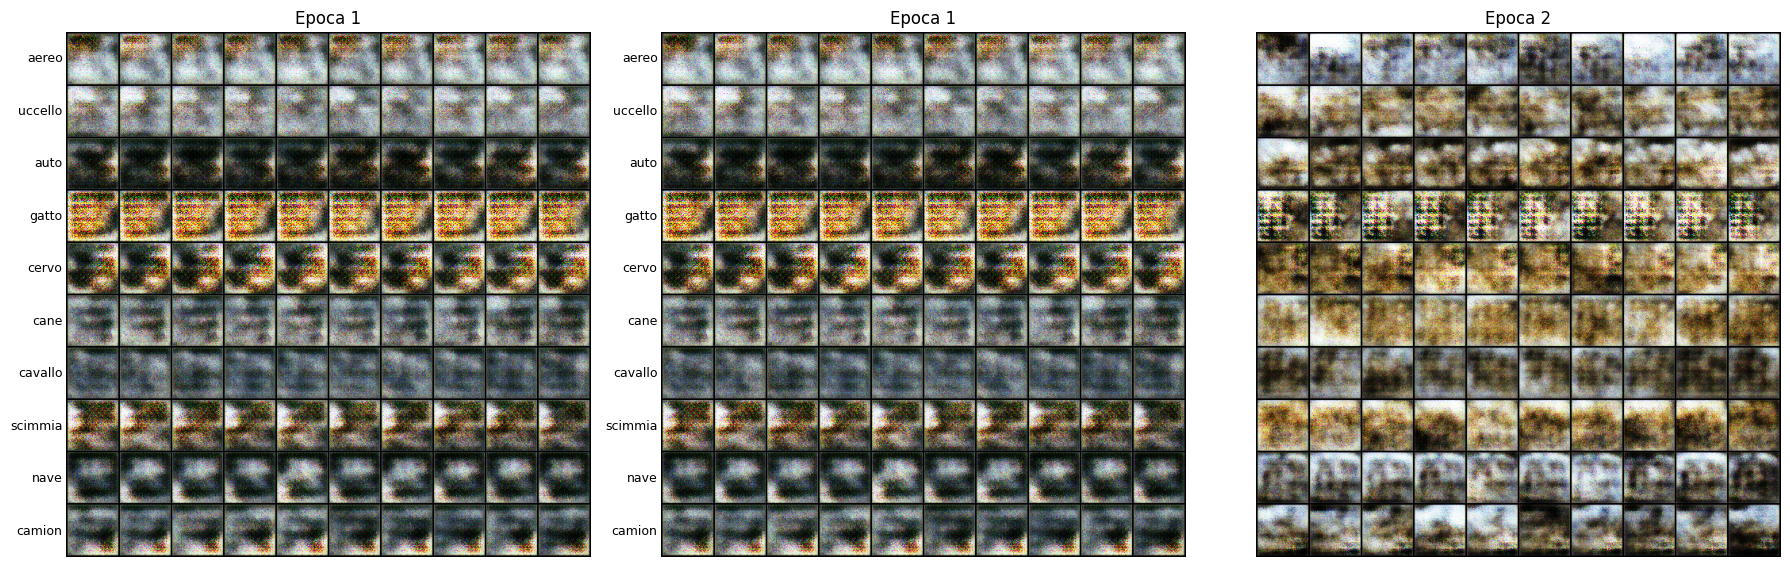

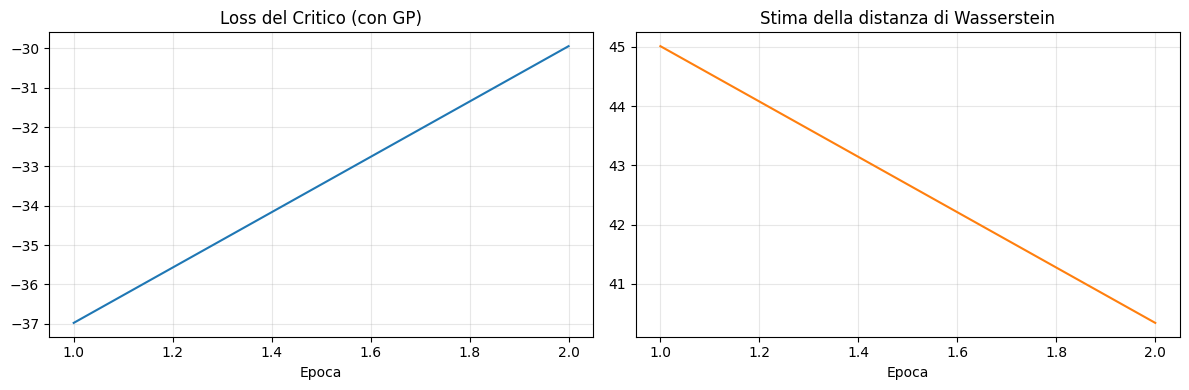

In [19]:
# --- FASE 4: CUSTOM TRAINING LOOP ---

# Funzione Gradient Penalty (Cuore della WGAN-GP)
# Questa funzione calcola la penalità necessaria per mantenere stabili i gradienti del Critico.
# Sostituisce il metodo di "tagliare" (clip) i pesi usato nelle WGAN originali.
# la norma (lunghezza) del gradiente del Critico dovrebbe essere esattamente 1 nei punti tra distribuzione reale e falsa
def compute_gradient_penalty(critic, labels, real_samples, fake_samples, device=device):
    # 1. Prendiamo un numero casuale (alpha) tra 0 e 1 per ogni immagine nel batch, di forma [batch_size, 1, 1, 1]
    alpha = torch.rand((real_samples.size(0), 1, 1, 1), device=device)
    
    # 2. Creiamo immagini "interpolate" che sono una via di mezzo tra quelle reali e quelle generate.
    # Matematicamente: inter = alpha * reale + (1-alpha) * fake
    # punti sulla retta tra un’immagine vera e una falsa. 
    # requires_grad_(True) serve per poter derivare rispetto a questi input
    interpolated = (alpha * real_samples + (1 - alpha) * fake_samples).requires_grad_(True)
    
    # 3. Chiediamo al Critico di valutare queste immagini ibride
    d_interpolated = critic(interpolated, labels)
    
    # 4. Calcoliamo il gradiente dell'output del critico rispetto alle immagini interpolate.
    #    Vogliamo sapere: "Quanto cambia il giudizio del critico se cambio leggermente l'immagine?"
    gradients = torch.autograd.grad(
        outputs=d_interpolated,
        inputs=interpolated,
        grad_outputs=torch.ones_like(d_interpolated),   # l’output è un vettore di punteggi (uno per immagine); questo equivale a sommarli
        create_graph=True,                              # Necessario per poter derivare nuovamente durante la backprop
    )[0]
    
    # 5. Calcoliamo la lunghezza (norma) di questo vettore gradiente
    gradients = gradients.view(gradients.size(0), -1)
    gradient_norm = gradients.norm(2, dim=1)
    
    # 6. La regola matematica (Lipschitz) dice che questa norma dovrebbe essere al massimo 1.
    # WGAN-GP penalizza la distanza di questa norma da 1. Cioè, vogliamo che la pendenza sia esattamente 1.
    penalty = torch.mean((gradient_norm - 1) ** 2)
    return penalty


# Ciclo di Training
snapshot_epochs = [1, epochs // 2, epochs]       # epoca 1, 25, 50 (conteggio da 1)

class_names = ["aereo", "uccello", "auto", "gatto", "cervo",
               "cane", "cavallo", "scimmia", "nave", "camion"]

# Rumore e etichette FISSI: così le gallerie si confrontano sugli stessi campioni
n_per_class = 10
fixed_labels = torch.arange(n_classes).repeat_interleave(n_per_class).to(device)   # (100,)
fixed_noise = torch.randn(n_classes * n_per_class, z_dim, 1, 1, device=device)     # (100, z_dim, 1, 1)

# Liste per il grafico finale
history_w_dist = []      # stima della distanza di Wasserstein per epoca
history_loss_C = []      # loss totale del Critico (con GP) per epoca
snapshots = {}           # epoca -> griglia di immagini


def genera_galleria(gen, epoch):
    """Genera la galleria delle classi (una riga per classe) e la salva su disco."""
    # BatchNorm in modalità inferenza
    gen.eval()                                    
    with torch.no_grad():
        fake = gen(fixed_noise, fixed_labels)
        # value_range fisso: senza, normalize=True usa min/max del batch e i colori cambiano tra epoche
        grid = make_grid(fake, nrow=n_per_class, normalize=True, value_range=(-1, 1)).cpu()
    gen.train()                                   # si torna in modalità training
    save_image(grid, os.path.join(DATA_DIR, f"galleria_epoca_{epoch}.png"))
    return grid

# # Inizializzazione dei modelli e spostamento sul dispositivo (CPU/GPU)
gen = Generator().to(device)
critic = Critic().to(device)

# Definizione degli ottimizzatori. Adam funziona bene con WGAN-GP.
# I parametri betas=(0.0, 0.9) sono standard per la stabilità delle WGAN-GP
opt_G = optim.Adam(gen.parameters(), lr=lr, betas=(0.0, 0.9))
opt_C = optim.Adam(critic.parameters(), lr=lr, betas=(0.0, 0.9))

for epoch in range(1, epochs + 1):               # epoche da 1 a 50
    w_dist_epoch, loss_C_epoch, n_steps = 0.0, 0.0, 0

    for real_imgs, labels in dataloader:
        # Spostiamo le immagini reali ed etichette sul device corretto
        real_imgs = real_imgs.to(device)
        labels = labels.to(device)
        # gestione dei batch di cui l'ultimo più piccolo (5.000 immagini con batch da 64)
        curr_batch_size = real_imgs.size(0)

        # --- FASE A: ADDESTRAMENTO DEL CRITICO ---
        # Il Critico viene aggiornato più volte (n_critic) per ogni passo del Generatore.
        # Questo assicura che il Generatore riceva un feedback di alta qualità.
        for _ in range(n_critic):
            # Pulizia dei gradienti precedenti
            opt_C.zero_grad()
            # Generiamo un batch di immagini false
            z = torch.randn(curr_batch_size, z_dim, 1, 1, device=device)
            # .detach(): non vogliamo aggiornare il generatore ora
            fake_imgs = gen(z, labels).detach()

            # Calcolo w_dist: differenza tra i punteggi medi delle immagini reali e false.
            # Il Critico vuole dare voti alti alle reali e bassi alle false.
            # Quindi vuole MASSIMIZZARE (C(reale) - C(fake)).
            # poiché PyTorch minimizza, si cambia segno: -(C(reale) - C(fake))
            w_dist = torch.mean(critic(real_imgs, labels)) - torch.mean(critic(fake_imgs, labels))

            # Calcolo della penalità del gradiente sulle immagini interpolate
            gp = compute_gradient_penalty(critic, labels, real_imgs, fake_imgs, device=device)

            # La Loss totale del Critico è la Loss WGAN più la penalità pesata
            loss_C = -w_dist + lambda_gp * gp

            # Calcolo dei gradienti e aggiornamento dei pesi del Critico
            loss_C.backward()
            opt_C.step()

        # --- FASE B: ADDESTRAMENTO DEL GENERATORE ---
        opt_G.zero_grad()

        # Generiamo nuove immagini false (questa volta senza detach, perché vogliamo addestrare il generatore)
        z = torch.randn(curr_batch_size, z_dim, 1, 1, device=device)
        fake_imgs = gen(z, labels)

        # Loss del Generatore: deve ingannare il Critico.
        # Vuole che il Critico dia un punteggio ALTO alle immagini fake.
        # Quindi vuole MASSIMIZZARE C(fake), che equivale a MINIMIZZARE -C(fake)
        loss_G = -torch.mean(critic(fake_imgs, labels))

        # Calcolo dei gradienti e aggiornamento dei pesi del Generatore
        loss_G.backward()
        opt_G.step()

        # Accumulo le statistiche dell'ultimo passo del Critico di questo batch
        w_dist_epoch += w_dist.item()
        loss_C_epoch += loss_C.item()
        n_steps += 1

    # Medie per epoca
    history_w_dist.append(w_dist_epoch / n_steps)
    history_loss_C.append(loss_C_epoch / n_steps)

    print(f"Epoca {epoch}/{epochs} | Loss Critico: {history_loss_C[-1]:.4f} | "
          f"Dist. Wasserstein: {history_w_dist[-1]:.4f} | Loss Gen: {loss_G.item():.4f} | GP: {gp.item():.4f}")


    # --- FASE 5: VALIDAZIONE E VISUALIZZAZIONE ---

    # Snapshot a inizio, metà e fine training 
    if epoch in snapshot_epochs:
        snapshots[epoch] = genera_galleria(gen, epoch)
        print(f"Salvata galleria per l'epoca {epoch}")

# 1) Le tre gallerie affiancate
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, ep in zip(axes, snapshot_epochs):
    ax.imshow(snapshots[ep].permute(1, 2, 0))
    ax.set_title(f"Epoca {ep}")
    ax.axis("off")
    # etichette di classe a sinistra: una per riga
    h = snapshots[ep].shape[1] / n_classes
    if ep == snapshot_epochs[0]:
        for i, name in enumerate(class_names):
            ax.text(-5, h * (i + 0.5), name, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "evoluzione_generazione.png"), dpi=150, bbox_inches="tight")
plt.show()

# 2) Andamento delle loss del Critico
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, epochs + 1), history_loss_C)
ax[0].set_title("Loss del Critico (con GP)")
ax[0].set_xlabel("Epoca"); ax[0].grid(alpha=0.3)

ax[1].plot(range(1, epochs + 1), history_w_dist, color="tab:orange")
ax[1].set_title("Stima della distanza di Wasserstein")
ax[1].set_xlabel("Epoca"); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "loss_critico.png"), dpi=150)
plt.show()

NOTE:

- la curva di Wasserstein è l’indicatore di convergenza principale: indica di quanto il Critico dà punteggi più alti alle immagini vere che a quelle generate. Un valore alto significa che il Critico distingue facilmente le due distribuzioni, quindi il Generatore è ancora lontano dalla realtà
- la loss del Critico segue lo stesso andamento perché ne contiene il termine con il segno cambiato: quando la distanza di Wasserstein scende, la loss sale. Il Critico minimizza questa quantità, quindi un valore molto negativo vuol dire che sta riuscendo bene a separare reale e falso.